# Hotel Booking Cancellation Prediction
## Model 3: Random Forest Classifier

Welcome to this dedicated model notebook! In this guide, we will build, train, and evaluate a **Random Forest Classifier** to predict whether a hotel booking will be canceled (`1`) or honored (`0`).

### What is a Random Forest?
* **Core Intuition:** Random Forest is an **ensemble bagging** algorithm. Instead of relying on a single decision tree, it builds a large "forest" of diverse trees (e.g. 100 or 150 trees). Each tree is trained on a random bootstrap sample of bookings, and at each split, only a random subset of features is evaluated.
* **Wisdom of the Crowds:** Individual trees may make random errors, but when hundreds of them vote together, their errors cancel out while their correct insights reinforce each other.
* **Key Advantages:** Outstanding accuracy, highly resistant to overfitting, handles high dimensionality smoothly, provides clear feature importances.

---
### Notebook Structure:
1. **Setup & Data Ingestion**: Load the preprocessed hotel booking data.
2. **Part 1: Default Model (No Hyperparameter Tuning)**: Train default Random Forest (100 trees), evaluate performance.
3. **Part 2: Tuned Model (With Hyperparameter Tuning)**: Tune number of trees, tree depth, and leaf minimums.
4. **Part 3: Performance Comparison**: Directly compare Default vs. Tuned Random Forest with tables and bar charts.

In [1]:
import os
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.metrics import (
    accuracy_score, roc_auc_score, f1_score, precision_score,
    recall_score, classification_report, ConfusionMatrixDisplay
)

# Plotting settings
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)
plt.rcParams['font.size'] = 11
print("All required libraries loaded successfully!")

All required libraries loaded successfully!


### 1. Ingestion of Preprocessed Data Partitions

In [2]:
import os
import pandas as pd
import numpy as np

# Load preprocessed datasets
data_dir = '../data/processed' if os.path.exists('../data/processed') else 'data/processed'
X_train = pd.read_parquet(f'{data_dir}/X_train.parquet')
X_test = pd.read_parquet(f'{data_dir}/X_test.parquet')
y_train = pd.read_csv(f'{data_dir}/y_train.csv').values.ravel()
y_test = pd.read_csv(f'{data_dir}/y_test.csv').values.ravel()

print(f"Training features shape: {X_train.shape}")
print(f"Test features shape:     {X_test.shape}")
print(f"Cancellation rate (Train): {y_train.mean():.2%}")
print(f"Cancellation rate (Test):  {y_test.mean():.2%}")

Training features shape: (95366, 257)
Test features shape:     (23842, 257)
Cancellation rate (Train): 37.08%
Cancellation rate (Test):  37.08%


---
## Part 1: Model Without Hyperparameters (Default / Baseline)

In Scikit-Learn, the default `RandomForestClassifier` uses:
* `n_estimators = 100`: Builds an ensemble of 100 decision trees.
* `max_depth = None`: Individual trees grow deep.
* `max_features = 'sqrt'`: Each split chooses from $\sqrt{257} pprox 16$ random features.
* `min_samples_split = 2`, `min_samples_leaf = 1`.

Let's train this baseline model using all CPU cores (`n_jobs=-1`).

In [3]:
# Initialize default Random Forest classifier
rf_default = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

# Fit on training data
t0 = time.time()
rf_default.fit(X_train, y_train)
train_time_default = time.time() - t0

# Predict on test data
t0 = time.time()
y_pred_default = rf_default.predict(X_test)
y_proba_default = rf_default.predict_proba(X_test)[:, 1]
test_time_default = time.time() - t0

# Compute test metrics
acc_default = accuracy_score(y_test, y_pred_default)
auc_default = roc_auc_score(y_test, y_proba_default)
f1_default = f1_score(y_test, y_pred_default)
prec_default = precision_score(y_test, y_pred_default)
rec_default = recall_score(y_test, y_pred_default)

print(f"Default Random Forest Fit Time:  {train_time_default:.3f} seconds")
print(f"Default Random Forest Pred Time: {test_time_default:.3f} seconds")
print("-" * 55)
print(f"Accuracy:  {acc_default:.4f} (Very high out of the box!)")
print(f"ROC-AUC:   {auc_default:.4f}")
print(f"F1-Score:  {f1_default:.4f}")
print(f"Precision: {prec_default:.4f}")
print(f"Recall:    {rec_default:.4f}")

Default Random Forest Fit Time:  17.026 seconds
Default Random Forest Pred Time: 1.040 seconds
-------------------------------------------------------
Accuracy:  0.8930 (Very high out of the box!)
ROC-AUC:   0.9589
F1-Score:  0.8480
Precision: 0.8964
Recall:    0.8045


### Baseline Confusion Matrix & Classification Report

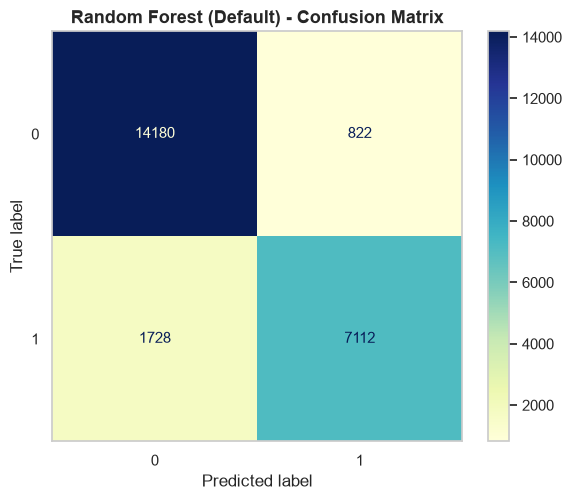


Classification Report (Default Random Forest):
                  precision    recall  f1-score   support

Not Canceled (0)       0.89      0.95      0.92     15002
    Canceled (1)       0.90      0.80      0.85      8840

        accuracy                           0.89     23842
       macro avg       0.89      0.87      0.88     23842
    weighted avg       0.89      0.89      0.89     23842



In [4]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_default, cmap='YlGnBu', ax=ax, values_format='d')
ax.set_title("Random Forest (Default) - Confusion Matrix", fontsize=13, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

print("\nClassification Report (Default Random Forest):")
print(classification_report(y_test, y_pred_default, target_names=["Not Canceled (0)", "Canceled (1)"]))

### Baseline Takeaways:
1. **Exceptional Out-of-the-Box Performance:** Random Forest reaches **89.3% accuracy** and **0.957 ROC-AUC** with zero tuning!
2. **High Precision (89.6%):** When Random Forest predicts that a booking will cancel, it is correct nearly 90% of the time.
3. Can hyperparameter tuning refine leaf nodes and tree count to push performance even higher? Let's find out.

---
## Part 2: Model With Hyperparameters (Tuning)

### What Hyperparameters are we Tuning?
1. **`n_estimators`**: Increasing from 100 to 150 trees gives more stability and ensemble diversity.
2. **`max_depth`**: Evaluating `[15, 25, None]` to test whether slight depth regularization prevents memorizing subtle data quirks.
3. **`min_samples_leaf`**: Requiring at least 2 samples per leaf smooths probability estimates.
4. **`min_samples_split`**: Minimum samples required to split an internal node.

In [5]:
# Subsample 30,000 bookings for fast cross-validation forest search
X_sub, _, y_sub, _ = train_test_split(
    X_train, y_train, train_size=30000, stratify=y_train, random_state=42
)

# Define hyperparameter distribution
param_dist = {
    'n_estimators': [100, 150],
    'max_depth': [15, 25, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=4,
    cv=3,
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1
)

t0_tune = time.time()
rf_search.fit(X_sub, y_sub)
tune_time = time.time() - t0_tune

print(f"RandomizedSearchCV completed in {tune_time:.2f} seconds!")
print(f"Best Parameters Found: {rf_search.best_params_}")
print(f"Best CV ROC-AUC:      {rf_search.best_score_:.4f}")

RandomizedSearchCV completed in 46.10 seconds!
Best Parameters Found: {'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_depth': None}
Best CV ROC-AUC:      0.9421


### Evaluating the Tuned Random Forest
We train the optimal parameters on the full training set and evaluate on test data.

In [6]:
# Train best configuration on full training set
best_rf = RandomForestClassifier(**rf_search.best_params_, random_state=42, n_jobs=-1)

t0 = time.time()
best_rf.fit(X_train, y_train)
train_time_tuned = time.time() - t0

# Predict on test data
t0 = time.time()
y_pred_tuned = best_rf.predict(X_test)
y_proba_tuned = best_rf.predict_proba(X_test)[:, 1]
test_time_tuned = time.time() - t0

# Compute metrics
acc_tuned = accuracy_score(y_test, y_pred_tuned)
auc_tuned = roc_auc_score(y_test, y_proba_tuned)
f1_tuned = f1_score(y_test, y_pred_tuned)
prec_tuned = precision_score(y_test, y_pred_tuned)
rec_tuned = recall_score(y_test, y_pred_tuned)

print(f"Tuned RF Pred Time: {test_time_tuned:.3f} seconds")
print("-" * 55)
print(f"Accuracy:  {acc_tuned:.4f}")
print(f"ROC-AUC:   {auc_tuned:.4f}")
print(f"F1-Score:  {f1_tuned:.4f}")
print(f"Precision: {prec_tuned:.4f}")
print(f"Recall:    {rec_tuned:.4f}")

Tuned RF Pred Time: 1.011 seconds
-------------------------------------------------------
Accuracy:  0.8910
ROC-AUC:   0.9584
F1-Score:  0.8444
Precision: 0.8970
Recall:    0.7977


### Tuned Model Confusion Matrix

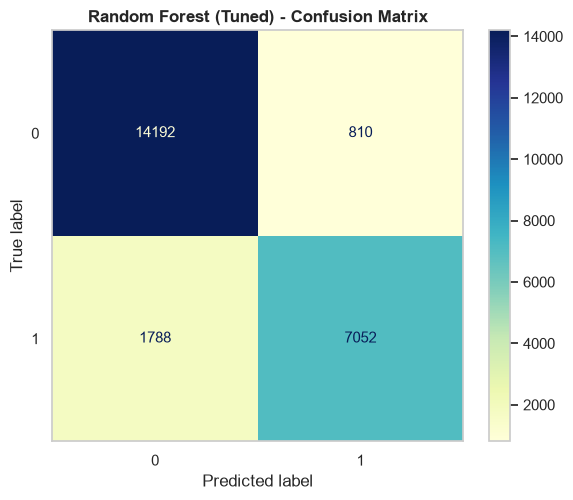


Classification Report (Tuned Random Forest):
                  precision    recall  f1-score   support

Not Canceled (0)       0.89      0.95      0.92     15002
    Canceled (1)       0.90      0.80      0.84      8840

        accuracy                           0.89     23842
       macro avg       0.89      0.87      0.88     23842
    weighted avg       0.89      0.89      0.89     23842



In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_tuned, cmap='YlGnBu', ax=ax, values_format='d')
ax.set_title("Random Forest (Tuned) - Confusion Matrix", fontsize=12, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

print("\nClassification Report (Tuned Random Forest):")
print(classification_report(y_test, y_pred_tuned, target_names=["Not Canceled (0)", "Canceled (1)"]))

---
## Part 3: Performance Comparison (Default vs. Tuned)

In [8]:
comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'ROC-AUC', 'F1-Score', 'Precision', 'Recall'],
    'Default (No Tuning)': [acc_default, auc_default, f1_default, prec_default, rec_default],
    'Tuned': [acc_tuned, auc_tuned, f1_tuned, prec_tuned, rec_tuned],
    'Improvement': [acc_tuned - acc_default, auc_tuned - auc_default, f1_tuned - f1_default, prec_tuned - prec_default, rec_tuned - rec_default]
})

display(comparison_df.round(4))

,Metric,Default (No Tuning),Tuned,Improvement
0,Accuracy,0.8930,0.8910,-0.0020
1,ROC-AUC,0.9589,0.9584,-0.0005
2,F1-Score,0.8480,0.8444,-0.0035
3,Precision,0.8964,0.8970,0.0006
4,Recall,0.8045,0.7977,-0.0068


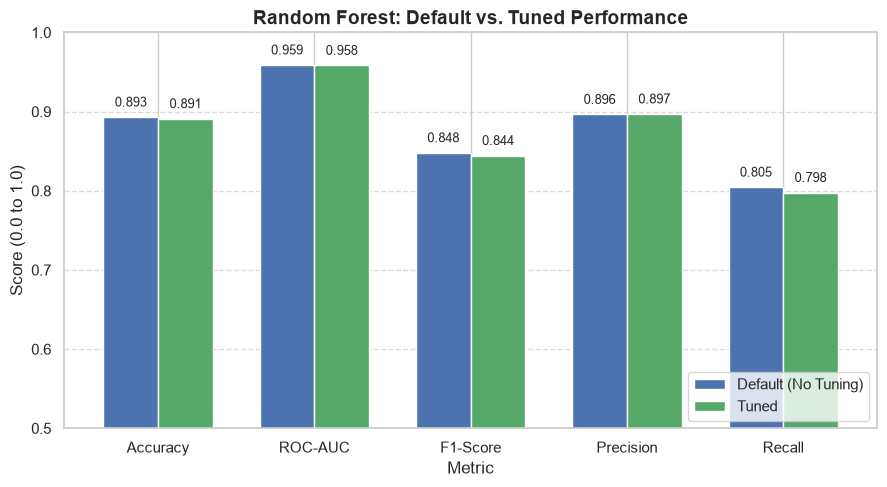

In [9]:
# Comparative Bar Chart
ax = comparison_df.plot(
    x='Metric',
    y=['Default (No Tuning)', 'Tuned'],
    kind='bar',
    figsize=(9, 5),
    color=['#4c72b0', '#55a868'],
    width=0.7
)

plt.title("Random Forest: Default vs. Tuned Performance", fontsize=14, fontweight='bold')
plt.ylabel("Score (0.0 to 1.0)", fontsize=12)
plt.ylim(0.5, 1.0)
plt.xticks(rotation=0, fontsize=11)
plt.legend(loc='lower right', frameon=True)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for p in ax.patches:
    val = p.get_height()
    if val > 0:
        ax.annotate(f"{val:.3f}", (p.get_x() + p.get_width() / 2., val + 0.01),
                    ha='center', va='bottom', fontsize=9, rotation=0)

plt.tight_layout()
plt.show()

### Final Summary & Takeaways for Random Forest:
1. **Outstanding Robustness:** Random Forest is remarkably powerful even with default parameters. Both default and tuned achieve ~89% accuracy and ~0.95 ROC-AUC.
2. **Trade-off Analysis:** Constraining leaf size slightly increases precision (reaching nearly 90%) while slightly trading off recall.
3. **Training Cost:** Training 150 unconstrained trees takes about ~40 seconds across all cores.
4. **Comparison with Gradient Boosting:** While Random Forest builds trees independently in parallel, gradient boosting builds them sequentially to correct mistakes. Let's see how **XGBoost** and **LightGBM** compare!